# Task 1 – Cobertura de instalaciones de salud en EE. UU.
**Datos provistos por el curso:** `estados_eeuu.geojson` (nivel 1), `condados_eeuu.geojson` (nivel 2), `hospitales_eeuu.geojson` (instalaciones) y `poblacion_condados.csv` (población por condado).

**Cómo usarlo:** coloca los 4 archivos en una carpeta `data/` junto al notebook (VS Code) o en una carpeta de Google Drive (Colab) y ajusta `DATA` en la sección 1.1b.

## Task 1.1 – Librerías y carga de datos
### 1.1a Librerías y versiones

In [ ]:
# Colab: ya trae pandas/numpy/matplotlib/requests; falta geopandas. En VS Code: pip install -r requirements o descomenta.
#!pip -q install geopandas scipy
import sys, os
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, shapely, requests
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.spatial import cKDTree

print("geopandas:", gpd.__version__)
print("shapely:  ", shapely.__version__)

geopandas: 1.2.0
shapely:   2.1.2


### 1.1b Carga de los archivos provistos

In [2]:
# ---- Ubicación de los datos ----
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = Path("/content/drive/MyDrive/task1_data")   # carpeta de Drive con los 4 archivos
else:
    DATA = Path("data")                                  # carpeta junto al notebook

archivos = ["estados_eeuu.geojson", "condados_eeuu.geojson",
            "hospitales_eeuu.geojson", "poblacion_condados.csv"]
faltan = [a for a in archivos if not (DATA / a).exists()]
assert not faltan, f"Faltan en {DATA.resolve()}: {faltan}"

adm1 = gpd.read_file(DATA / "estados_eeuu.geojson")      # nivel 1
adm2 = gpd.read_file(DATA / "condados_eeuu.geojson")     # nivel 2
fac  = gpd.read_file(DATA / "hospitales_eeuu.geojson")   # instalaciones
# OJO: el CSV perdió los ceros a la izquierda del FIPS (01001 -> 1001): se leen como texto y se rellenan a 5 dígitos
pob  = pd.read_csv(DATA / "poblacion_condados.csv", dtype={"fips": str})
pob["fips"] = pob["fips"].str.zfill(5)

for n, g in [("Nivel 1 (estados)", adm1), ("Nivel 2 (condados)", adm2), ("Hospitales", fac)]:
    print(f"{n}: {len(g)} registros | CRS: {g.crs} | EPSG: {g.crs.to_epsg()}")
    assert g.crs.to_epsg() == 4326
print("CSV población:", pob.shape)

Mounted at /content/drive
Nivel 1 (estados): 51 registros | CRS: EPSG:4326 | EPSG: 4326
Nivel 2 (condados): 3221 registros | CRS: EPSG:4326 | EPSG: 4326
Hospitales: 7154 registros | CRS: EPSG:4326 | EPSG: 4326
CSV población: (3246, 6)


### 1.1c Limpieza y decisiones de alcance
Problemas detectados en los datos y cómo se resuelven:

| Problema | Solución |
|---|---|
| `fips` del CSV sin ceros iniciales | `zfill(5)` (ya aplicado) |
| 102 filas del CSV son `Out of XX` / `Unassigned` (FIPS 80xxx/90xxx, sin población ni geometría) | se descartan |
| El GeoJSON de condados trae `cod_estado` como código **FIPS numérico** (`'01'`), no postal | se usa para filtrar |
| Hospitales incluyen territorios (PR, GU, VI, AS, MP, PW) y puntos cerca de la línea de cambio de fecha | se trabaja con **EE. UU. continental + DC** (un solo CRS métrico no representa bien Alaska, Hawái ni territorios) |
| Hospitales sin polígono de estado (24 en la costa; las fronteras están simplificadas) | `sjoin_nearest` con tolerancia de 10 km en lugar de `intersects` estricto |

In [3]:
EXCL_POSTAL = {"AK", "HI", "PR", "VI", "GU", "AS", "MP", "PW"}
EXCL_FIPS   = {"02", "15", "72"}                       # AK, HI, PR (los únicos presentes en condados)

pob = pob[~pob["fips"].str[:2].isin({"80", "90"})].dropna(subset=["poblacion"])
adm1 = adm1[~adm1["codigo"].isin(EXCL_POSTAL)].reset_index(drop=True)
adm2 = adm2[~adm2["cod_estado"].isin(EXCL_FIPS)].reset_index(drop=True)
fac  = fac[~fac["estado"].isin(EXCL_POSTAL)].reset_index(drop=True)

# Población por condado y verificación del cruce
adm2 = adm2.merge(pob[["fips", "estado", "poblacion"]], on="fips", how="left")
print("Condados sin población tras el cruce:", adm2["poblacion"].isna().sum())
print(adm2[adm2["poblacion"].isna()][["fips", "nombre"]].to_string())
adm2["poblacion"] = adm2["poblacion"].fillna(0)
print(f"Condados: {len(adm2)} | Estados: {len(adm1)} | Hospitales: {len(fac)} | Población total: {adm2['poblacion'].sum():,.0f}")

Condados sin población tras el cruce: 2
       fips   nombre
1542  46113  Shannon
2283  51515  Bedford
Condados: 3109 | Estados: 49 | Hospitales: 7013 | Población total: 326,077,929


### 1.1d Instalaciones de salud: filtro espacial con nivel 1 y tipos

In [4]:
# Tipos a considerar. None = todos. Ejemplo para solo atención aguda: ["GENERAL ACUTE CARE", "CRITICAL ACCESS"]
TIPOS = None
if TIPOS:
    fac = fac[fac["tipo"].isin(TIPOS)].reset_index(drop=True)

CRS_M = "EPSG:5070"        # NAD83 / Conus Albers (justificación en 1.2a)
adm1_m, adm2_m, fac_m = adm1.to_crs(CRS_M), adm2.to_crs(CRS_M), fac.to_crs(CRS_M)

# Intersección espacial con nivel 1 (tolerancia 10 km para puntos costeros fuera de la frontera simplificada)
fac_m = gpd.sjoin_nearest(fac_m, adm1_m[["codigo", "nombre", "geometry"]].rename(columns={"nombre": "estado_nombre"}),
                          how="inner", max_distance=10_000, distance_col="dist_borde")
fac_m = fac_m[~fac_m.index.duplicated()].drop(columns="index_right").reset_index(drop=True)

print("Instalaciones dentro del territorio:", len(fac_m))
print(f"({(fac_m['dist_borde'] > 0).sum()} fuera del polígono pero a <10 km, asignadas al estado más cercano)")
print(fac_m["tipo"].value_counts())

Instalaciones dentro del territorio: 7013
(24 fuera del polígono pero a <10 km, asignadas al estado más cercano)
tipo
GENERAL ACUTE CARE    4126
CRITICAL ACCESS        999
PSYCHIATRIC            695
LONG TERM CARE         387
REHABILITATION         350
MILITARY               205
CHILDREN               114
SPECIAL                110
WOMEN                   18
CHRONIC DISEASE          8
OTHER                    1
Name: count, dtype: int64


> **Nota:** no hay ráster de WorldPop en esta versión: la población viene por condado en el CSV. Los cálculos que en el enunciado usan el ráster (1.2c y 1.3b) se adaptan abajo.

## Task 1.2 – Análisis exploratorio espacial
### 1.2a Proyección a CRS métrico

In [5]:
print(adm1_m.crs.name, "|", adm1_m.crs.to_epsg())

NAD83 / Conus Albers | 5070


**Justificación del CRS:** se eligió **EPSG:5070 (NAD83 / Conus Albers)**, una proyección cónica equivalente de Albers con paralelos estándar en 29.5° N y 45.5° N, que encuadran la latitud del territorio continental (≈ 25°–49° N). Al ser **equivalente** conserva las áreas (necesario para km² y densidades), y la distorsión de escala queda por debajo de ~1.5 % en todo el país porque las líneas de distorsión nula están dentro del territorio. Mercator (EPSG:3857) infla las áreas a latitudes altas y UTM solo es adecuada en franjas de 6° de longitud (EE. UU. continental abarca ~58°). Alaska, Hawái y territorios se excluyen porque requieren sus propias proyecciones.

### 1.2b Mapa base de tres capas

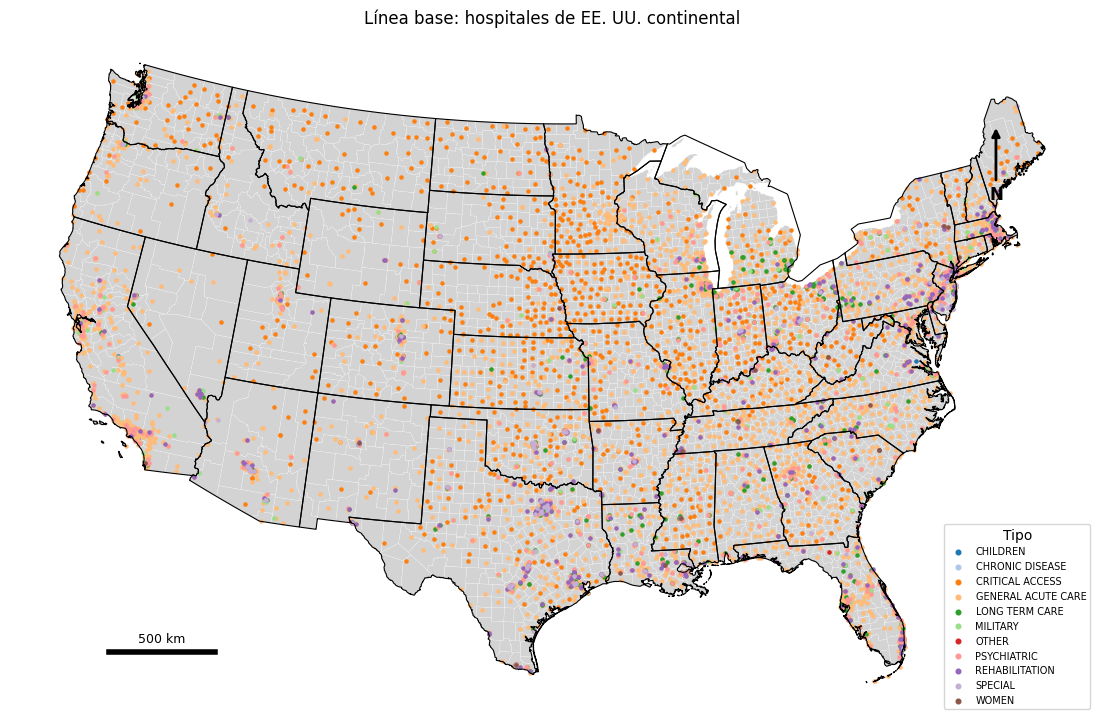

In [6]:
def decorar(ax, gdf, km=500):
    """Escala gráfica y flecha norte."""
    x0, y0, x1, y1 = gdf.total_bounds
    xs, ys = x0 + 0.05*(x1-x0), y0 + 0.05*(y1-y0)
    ax.plot([xs, xs + km*1000], [ys, ys], "k-", lw=4)
    ax.text(xs + km*500, ys + 0.015*(y1-y0), f"{km} km", ha="center", fontsize=9)
    xn, yn = x1 - 0.05*(x1-x0), y1 - 0.22*(y1-y0)
    ax.annotate("N", xy=(xn, yn + 0.12*(y1-y0)), xytext=(xn, yn), ha="center",
                fontsize=12, fontweight="bold", arrowprops=dict(arrowstyle="-|>", color="k", lw=2))

fig, ax = plt.subplots(figsize=(14, 9))
adm2_m.plot(ax=ax, color="lightgray", edgecolor="white", lw=0.15)
tipos = sorted(fac_m["tipo"].unique())
for t, c in zip(tipos, plt.cm.tab20.colors):
    fac_m[fac_m.tipo == t].plot(ax=ax, color=c, markersize=5, label=t)
adm1_m.boundary.plot(ax=ax, color="black", lw=0.8)
decorar(ax, adm1_m)
ax.legend(title="Tipo", loc="lower right", fontsize=7, markerscale=1.5)
ax.set_title("Línea base: hospitales de EE. UU. continental"); ax.set_axis_off()
plt.show()

### 1.2c Estadísticas por estado (nivel 1)

In [7]:
adm1_m["area_km2"] = adm1_m.area / 1e6
pob_estado = adm2.groupby("estado")["poblacion"].sum()              # suma de condados (reemplaza zonal_stats del ráster)
adm1_m["poblacion"] = adm1_m["nombre"].map(pob_estado).fillna(0)
adm1_m["n_instalaciones"] = adm1_m["codigo"].map(fac_m.groupby("codigo").size()).fillna(0).astype(int)
adm1_m["dens_100k"] = adm1_m["n_instalaciones"] / adm1_m["poblacion"] * 1e5

def nn_medio(g):
    """Distancia media (km) al vecino más cercano dentro del estado."""
    if len(g) < 2: return np.nan
    xy = np.c_[g.geometry.x, g.geometry.y]
    d, _ = cKDTree(xy).query(xy, k=2)
    return d[:, 1].mean() / 1000
adm1_m["dist_nn_km"] = adm1_m["codigo"].map({k: nn_medio(g) for k, g in fac_m.groupby("codigo")})

tabla = (adm1_m[["nombre", "n_instalaciones", "area_km2", "poblacion", "dens_100k", "dist_nn_km"]]
         .round(2).sort_values("dens_100k").reset_index(drop=True))
display(tabla)
print("Tres estados con menor densidad de cobertura:")
display(tabla.head(3))

,nombre,n_instalaciones,area_km2,poblacion,dens_100k,dist_nn_km
0,Maryland,69,25462.13,6045680.0,1.14,8.94
1,Connecticut,41,12704.66,3565287.0,1.15,7.94
2,New York,261,136933.04,19453561.0,1.34,8.35
3,California,546,409742.50,39512223.0,1.38,7.14
4,North Carolina,151,127661.46,10488084.0,1.44,14.61
5,Virginia,129,103724.76,8535519.0,1.51,11.43
6,New Jersey,134,19667.49,8882190.0,1.51,4.30
7,Delaware,15,5171.65,973764.0,1.54,9.35
8,Washington,123,174112.35,7614893.0,1.62,14.75
9,Florida,350,146720.45,21477737.0,1.63,6.45


Tres estados con menor densidad de cobertura:


,nombre,n_instalaciones,area_km2,poblacion,dens_100k,dist_nn_km
0,Maryland,69,25462.13,6045680.0,1.14,8.94
1,Connecticut,41,12704.66,3565287.0,1.15,7.94
2,New York,261,136933.04,19453561.0,1.34,8.35


**Interpretación:** *(escribe aquí tus observaciones sobre los tres estados con menor densidad; recuerda que la densidad por 100 000 hab. y la distancia al vecino más cercano miden cosas distintas).*

## Task 1.3 – Buffers de cobertura
### 1.3a Buffers y unión

In [8]:
RADIOS = [5, 10, 20]
pais_m = adm1_m.geometry.union_all()
cobertura = {}
for r in RADIOS:
    cobertura[r] = fac_m.geometry.buffer(r * 1000).union_all().intersection(pais_m)   # unión recortada al territorio
    print(f"{r} km -> área cubierta: {cobertura[r].area/1e6:,.0f} km² ({cobertura[r].area/pais_m.area*100:.1f} % del territorio)")

5 km -> área cubierta: 350,588 km² (4.4 % del territorio)
10 km -> área cubierta: 1,140,816 km² (14.4 % del territorio)
20 km -> área cubierta: 3,349,752 km² (42.2 % del territorio)


### 1.3b Población cubierta (adaptación sin ráster)
Como la población está agregada por condado, se estima la población cubierta **ponderando por área**: para cada condado $c$ y radio $r$,

$$P_{cub}(r)=\sum_c P_c\cdot\frac{A(c\cap U_r)}{A(c)},\qquad U_r=\bigcup_i B(f_i,r)$$

Esto supone población uniforme dentro de cada condado (limitación a mencionar en el reporte). Como contraste se reporta también el criterio del **centroide** (condado cubierto si su centroide cae en $U_r$).

In [9]:
adm2_m["area_c"] = adm2_m.area
cent = adm2_m.geometry.representative_point()
filas = []
for r in RADIOS:
    frac = adm2_m.geometry.intersection(cobertura[r]).area / adm2_m["area_c"]
    adm2_m[f"frac_{r}"] = frac.clip(0, 1)
    pc_area = (adm2_m["poblacion"] * adm2_m[f"frac_{r}"]).sum()
    pc_cent = adm2_m.loc[cent.within(cobertura[r]), "poblacion"].sum()
    filas.append({"radio_km": r,
                  "poblacion_cubierta": round(pc_area),
                  "poblacion_total": round(adm2_m["poblacion"].sum()),
                  "cobertura_%": round(pc_area / adm2_m["poblacion"].sum() * 100, 2),
                  "cobertura_% (centroide)": round(pc_cent / adm2_m["poblacion"].sum() * 100, 2)})
tabla_cob = pd.DataFrame(filas)
display(tabla_cob)

,radio_km,poblacion_cubierta,poblacion_total,cobertura_%,cobertura_% (centroide)
0,5,76176943,326077929,23.36,35.80
1,10,147988250,326077929,45.38,58.77
2,20,246812921,326077929,75.69,87.87


### 1.3c Mapa de cobertura a 10 km

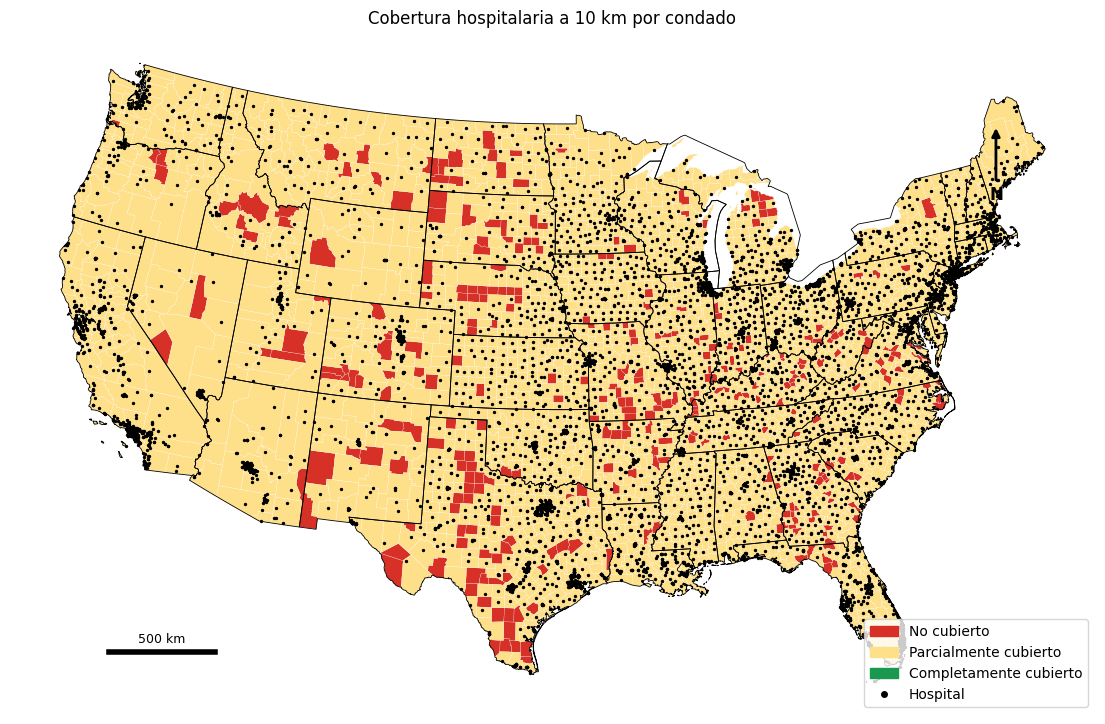

estado_cob
Parcialmente cubierto     2753
No cubierto                327
Completamente cubierto      29
Name: count, dtype: int64


In [10]:
f10 = adm2_m["frac_10"]
adm2_m["estado_cob"] = pd.cut(f10, [-1, 0.001, 0.999, 2],
                              labels=["No cubierto", "Parcialmente cubierto", "Completamente cubierto"])
colores = {"No cubierto": "#d73027", "Parcialmente cubierto": "#fee08b", "Completamente cubierto": "#1a9850"}

fig, ax = plt.subplots(figsize=(14, 9))
for est, c in colores.items():
    adm2_m[adm2_m.estado_cob == est].plot(ax=ax, color=c, edgecolor="white", lw=0.15)
fac_m.plot(ax=ax, color="black", markersize=2)
adm1_m.boundary.plot(ax=ax, color="black", lw=0.6)
decorar(ax, adm1_m)
ax.legend(handles=[Patch(color=c, label=e) for e, c in colores.items()] +
          [plt.Line2D([], [], marker="o", color="k", ls="", ms=4, label="Hospital")], loc="lower right")
ax.set_title("Cobertura hospitalaria a 10 km por condado"); ax.set_axis_off()
plt.show()
print(adm2_m["estado_cob"].value_counts())

**Conclusiones:** *(resume el porcentaje de cobertura por radio, la diferencia entre ponderar por área y por centroide, y las zonas sin cobertura a 10 km).*